# France Power Demand Forecasting: LightGBM + SHAP

Next-day (D+1) forecast of French national electricity demand, tested on 2024 and 2025, and explained with SHAP.

**Result:** LightGBM averages **0.89 GW MAE (1.69% MAPE)**, 61% lower than the best baseline (2.30 GW).

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rumi17Git/france-power-forecast/blob/main/notebook.ipynb)

Run top to bottom (Runtime > Run all). CPU is enough.

In [1]:
!pip install -q lightgbm shap holidays

## Setup

Libraries, a fixed random seed so results repeat exactly, and output folders.

In [2]:
import os
import warnings
from datetime import date, timedelta

import holidays
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import shap

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)
START = "2015-01-01"

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
plt.rcParams["figure.dpi"] = 110

## Step 1. Load the data

RTE national consumption from ODRE: the consolidated history (`eco2mix-national-cons-def`) plus real-time data (`eco2mix-national-tr`) for the days after it ends. Paris daily temperature from the Open-Meteo archive.

In [3]:
ODRE = ("https://odre.opendatasoft.com/api/explore/v2.1/catalog/datasets/"
        "{}/exports/parquet?timezone=Europe%2FParis")
DATASETS = ["eco2mix-national-cons-def", "eco2mix-national-tr"]

raw = {}
for name in DATASETS:
    raw[name] = pd.read_parquet(ODRE.format(name))
    print(f"{name}: {raw[name].shape[0]:,} rows")
    print("  columns:", raw[name].columns.tolist())

display(raw[DATASETS[0]].head())

eco2mix-national-cons-def: 514,272 rows
  columns: ['perimetre', 'nature', 'date', 'heure', 'date_heure', 'consommation', 'prevision_j1', 'prevision_j', 'fioul', 'charbon', 'gaz', 'nucleaire', 'eolien', 'solaire', 'hydraulique', 'pompage', 'bioenergies', 'ech_physiques', 'taux_co2', 'ech_comm_angleterre', 'ech_comm_espagne', 'ech_comm_italie', 'ech_comm_suisse', 'ech_comm_allemagne_belgique', 'fioul_tac', 'fioul_cogen', 'fioul_autres', 'gaz_tac', 'gaz_cogen', 'gaz_ccg', 'gaz_autres', 'hydraulique_fil_eau_eclusee', 'hydraulique_lacs', 'hydraulique_step_turbinage', 'bioenergies_dechets', 'bioenergies_biomasse', 'bioenergies_biogaz']
eco2mix-national-tr: 7,872 rows
  columns: ['perimetre', 'nature', 'date', 'heure', 'date_heure', 'consommation', 'prevision_j1', 'prevision_j', 'fioul', 'charbon', 'gaz', 'nucleaire', 'eolien', 'eolien_terrestre', 'eolien_offshore', 'solaire', 'hydraulique', 'pompage', 'bioenergies', 'ech_physiques', 'taux_co2', 'ech_comm_angleterre', 'ech_comm_espagne', 'ec

,perimetre,nature,date,heure,date_heure,consommation,prevision_j1,prevision_j,fioul,charbon,...,gaz_tac,gaz_cogen,gaz_ccg,gaz_autres,hydraulique_fil_eau_eclusee,hydraulique_lacs,hydraulique_step_turbinage,bioenergies_dechets,bioenergies_biomasse,bioenergies_biogaz
0,France,Données consolidées,2026-08-31,23:45,2026-08-31 23:45:00+02:00,NaN,42850,42250,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,France,Données consolidées,2026-08-31,23:30,2026-08-31 23:30:00+02:00,43979.0,44200,43000,55.0,15.0,...,27.0,172,2969.0,51.0,2225.0,1405.0,681.0,485.0,403.0,291.0
2,France,Données consolidées,2026-08-31,23:15,2026-08-31 23:15:00+02:00,NaN,44850,43750,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,France,Données consolidées,2026-08-31,23:00,2026-08-31 23:00:00+02:00,45070.0,45500,44500,55.0,15.0,...,26.0,177,3016.0,51.0,2278.0,1869.0,806.0,484.0,402.0,292.0
4,France,Données consolidées,2026-08-31,22:45,2026-08-31 22:45:00+02:00,NaN,45100,44150,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
def to_points(df, source):
    # One row per reading: the local calendar day and the consumption in MW.
    if "perimetre" in df.columns:
        df = df[df["perimetre"].astype(str).str.lower() == "france"]
    if "date" in df.columns:
        day = pd.to_datetime(df["date"].astype(str)).dt.normalize()
    else:
        ts = pd.to_datetime(df["date_heure"])
        ts = (ts.dt.tz_localize("Europe/Paris", ambiguous="NaT", nonexistent="NaT")
              if ts.dt.tz is None else ts.dt.tz_convert("Europe/Paris"))
        day = ts.dt.tz_localize(None).dt.normalize()
    out = pd.DataFrame({
        "day": day.values,
        "consommation": pd.to_numeric(df["consommation"], errors="coerce").values,
        "source": source,
    })
    return out.dropna(subset=["day", "consommation"])

cons = to_points(raw["eco2mix-national-cons-def"], "consolidated")
rt = to_points(raw["eco2mix-national-tr"], "real-time")

# Keep real-time readings only for days after the consolidated data ends.
rt = rt[rt["day"] > cons["day"].max()]
points = pd.concat([cons, rt], ignore_index=True)
points = points[points["day"] >= START]

for src, g in points.groupby("source"):
    print(f"{src:>12}: {g['day'].min().date()} to {g['day'].max().date()}")

consolidated: 2015-01-01 to 2026-08-31
   real-time: 2026-09-01 to 2026-11-20


In [5]:
# Paris daily mean temperature. The archive runs a few days behind today.
last_day = min(points["day"].max().date(), date.today() - timedelta(days=3))
url = ("https://archive-api.open-meteo.com/v1/archive?latitude=48.85&longitude=2.35"
       f"&start_date={START}&end_date={last_day}"
       "&daily=temperature_2m_mean&timezone=Europe/Paris")
w = requests.get(url, timeout=120).json()
weather = pd.DataFrame({
    "day": pd.to_datetime(w["daily"]["time"]),
    "temp": w["daily"]["temperature_2m_mean"],
}).set_index("day")

print(f"weather: {weather.index.min().date()} to {weather.index.max().date()}, "
      f"{weather['temp'].isna().sum()} missing values")

weather: 2015-01-01 to 2026-11-17, 0 missing values


## Step 2. Build the daily table

One row per day: average load in GW and temperature. Days with too few readings are dropped, and every calendar day is kept on the index so `shift(1)` always means yesterday.

In [6]:
agg = (points.groupby(["day", "source"])["consommation"]
       .agg(load_mw="mean", n_readings="count")
       .reset_index())
agg["typical"] = agg.groupby("source")["n_readings"].transform("median")
short = agg["n_readings"] < 0.9 * agg["typical"]
print(f"Dropped {short.sum()} days with too few readings:",
      agg.loc[short, "day"].dt.date.tolist()[:10])
agg = agg[~short]

assert not agg["day"].duplicated().any(), "duplicate days"

daily = (agg.set_index("day")[["load_mw"]]
         .join(weather, how="inner")
         .sort_index())
daily["load_gw"] = daily.pop("load_mw") / 1000
daily = daily[["load_gw", "temp"]]

# Put every calendar day on the index, so a shift of 1 always means yesterday.
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing = full_range.difference(daily.index)
daily = daily.reindex(full_range)
daily.index.name = "day"
print(f"{len(daily):,} days from {daily.index.min().date()} to {daily.index.max().date()}, "
      f"{len(missing)} missing days")
daily.head()

Dropped 0 days with too few readings: []
4,339 days from 2015-01-01 to 2026-11-17, 0 missing days


,load_gw,temp
day,,
2015-01-01,67.242375,-0.7
2015-01-02,69.001896,4.9
2015-01-03,64.094208,6.3
2015-01-04,58.878667,4.0
2015-01-05,71.274979,0.3


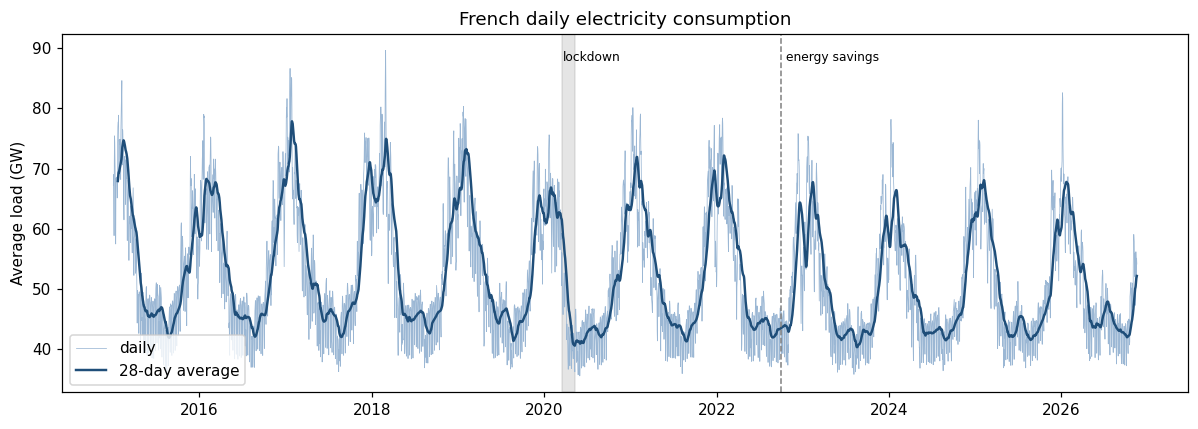

Average load by year (GW):
day
2015    54.0
2016    54.7
2017    54.7
2018    54.3
2019    53.7
2020    50.8
2021    53.5
2022    51.4
2023    49.7
2024    50.1
2025    50.7
2026    49.6


In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily["load_gw"], lw=0.5, color="#9bb7d4", label="daily")
ax.plot(daily.index, daily["load_gw"].rolling(28, min_periods=20).mean(),
        lw=1.6, color="#1f4e79", label="28-day average")
ax.axvspan(pd.Timestamp("2020-03-17"), pd.Timestamp("2020-05-11"), color="grey", alpha=0.2)
ax.text(pd.Timestamp("2020-03-20"), ax.get_ylim()[1] * 0.97, "lockdown", fontsize=8, va="top")
ax.axvline(pd.Timestamp("2022-10-01"), color="grey", ls="--", lw=1)
ax.text(pd.Timestamp("2022-10-20"), ax.get_ylim()[1] * 0.97, "energy savings", fontsize=8, va="top")
ax.set_ylabel("Average load (GW)")
ax.set_title("French daily electricity consumption")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("figures/01_daily_load.png")
plt.show()

print("Average load by year (GW):")
print(daily["load_gw"].groupby(daily.index.year).mean().round(1).to_string())

In [8]:
# Test years = the last two full calendar years in the data.
end = daily.index.max()
last_full = end.year if (end.month, end.day) == (12, 31) else end.year - 1
TEST_YEARS = [last_full - 1, last_full]

for y in TEST_YEARS:
    n = daily.loc[str(y), "load_gw"].notna().sum()
    print(f"{y}: {n} days with data" + ("" if n >= 355 else "  <- check this year"))
print("Test years:", TEST_YEARS)

2024: 366 days with data
2025: 365 days with data
Test years: [2024, 2025]


## Step 3. Baselines

Two simple forecasts every model must beat: **naive** (tomorrow = today) and **seasonal naive** (tomorrow = same weekday last week). Scored with MAE, RMSE (GW) and MAPE (%).

In [9]:
def metrics(y_true, y_pred):
    err = y_true - y_pred
    return {
        "MAE (GW)": np.mean(np.abs(err)),
        "RMSE (GW)": np.sqrt(np.mean(err ** 2)),
        "MAPE (%)": 100 * np.mean(np.abs(err) / y_true),
    }

baselines = pd.DataFrame({
    "actual": daily["load_gw"],
    "Naive": daily["load_gw"].shift(1),
    "Seasonal naive": daily["load_gw"].shift(7),
})

rows = []
for y in TEST_YEARS:
    b = baselines.loc[str(y)].dropna()
    for name in ["Naive", "Seasonal naive"]:
        rows.append({"model": name, "test year": y, **metrics(b["actual"], b[name])})
baseline_results = pd.DataFrame(rows)
baseline_results.round(2)

,model,test year,MAE (GW),RMSE (GW),MAPE (%)
0,Naive,2024,2.30,3.09,4.70
1,Seasonal naive,2024,3.12,4.67,5.81
2,Naive,2025,2.29,3.06,4.63
3,Seasonal naive,2025,3.27,4.91,6.04


## Step 4. Features without leakage

Everything is known by the end of day t-1, except temperature: the real temperature of day t is an **oracle** feature (a perfect weather forecast). The no-weather model in step 5 shows the other extreme.

In [10]:
FR_HOLIDAYS = holidays.France(years=range(2015, date.today().year + 2))

def build_features(daily):
    d = daily.copy()
    d["lag_1"] = d["load_gw"].shift(1)
    d["lag_7"] = d["load_gw"].shift(7)
    d["lag_14"] = d["load_gw"].shift(14)
    d["roll_7"] = d["load_gw"].shift(1).rolling(7).mean()
    d["dow"] = d.index.dayofweek
    d["month"] = d.index.month
    d["doy"] = d.index.dayofyear
    d["is_holiday"] = d.index.map(lambda x: x in FR_HOLIDAYS).astype(int)
    d["hdd"] = (15.5 - d["temp"]).clip(lower=0)
    d["cdd"] = (d["temp"] - 22).clip(lower=0)
    return d.dropna()

FEATURES_ALL = ["lag_1", "lag_7", "lag_14", "roll_7", "dow", "month", "doy",
                "is_holiday", "temp", "hdd", "cdd"]
FEATURES_NO_WEATHER = [f for f in FEATURES_ALL if f not in ("temp", "hdd", "cdd")]
FEATURES_MONO = [f for f in FEATURES_ALL if f != "temp"]

feat = build_features(daily)
print(f"{len(feat):,} rows, {len(FEATURES_ALL)} features")
feat[FEATURES_ALL + ["load_gw"]].tail()

4,325 rows, 11 features


,lag_1,lag_7,lag_14,roll_7,dow,month,doy,is_holiday,temp,hdd,cdd,load_gw
day,,,,,,,,,,,,
2026-11-13,52.876812,57.823167,51.015958,53.328150,4,11,317,0,6.2,9.3,0.0,56.201135
2026-11-14,56.201135,53.479469,47.127344,53.096432,5,11,318,0,4.4,11.1,0.0,54.902948
2026-11-15,54.902948,52.118313,46.935646,53.299786,6,11,319,0,8.8,6.7,0.0,51.206010
2026-11-16,51.206010,55.984448,54.073979,53.169457,0,11,320,0,10.2,5.3,0.0,55.130302
2026-11-17,55.130302,53.684010,56.637344,53.047436,1,11,321,0,13.7,1.8,0.0,54.166802


In [11]:
# Leakage check: rebuild the features using only data up to day t.
# If row t is identical, no feature looked into the future.
check_days = feat.loc[str(TEST_YEARS[0])].index[[10, 100, 200]]
for t in check_days:
    cut = build_features(daily.loc[:t])
    pd.testing.assert_series_equal(cut.loc[t, FEATURES_ALL], feat.loc[t, FEATURES_ALL])
print("Leakage check passed on", [t.date() for t in check_days])

Leakage check passed on [datetime.date(2024, 1, 11), datetime.date(2024, 4, 10), datetime.date(2024, 7, 19)]


## Step 5. LightGBM with time-based validation

Never a random split. Each fold trains on the past, stops early on the next year, and is tested on the year after. Three versions: all features, no weather (ablation), and monotone (demand can never fall when it gets colder; trained with L2 because LightGBM refuses monotone constraints with L1).

In [12]:
FOLDS = [{"train_end": y - 2, "val": y - 1, "test": y} for y in TEST_YEARS]
pd.DataFrame(FOLDS).rename(columns={"train_end": "train up to", "val": "early-stopping year",
                                    "test": "test year"})

,train up to,early-stopping year,test year
0,2022,2023,2024
1,2023,2024,2025


In [13]:
VERSIONS = {
    "LightGBM": {"features": FEATURES_ALL},
    "LightGBM, no weather": {"features": FEATURES_NO_WEATHER},
    # LightGBM does not allow monotone constraints with the L1 objective,
    # so this version uses L2 (squared error) instead.
    "LightGBM, monotone": {"features": FEATURES_MONO, "objective": "l2",
                           "monotone_constraints": [1 if f == "hdd" else 0 for f in FEATURES_MONO]},
}

def fit_lgbm(X_train, y_train, X_val, y_val, objective="l1", **extra):
    model = lgb.LGBMRegressor(
        objective=objective, learning_rate=0.03, n_estimators=3000,
        num_leaves=31, min_child_samples=20, colsample_bytree=0.8,
        random_state=SEED, verbose=-1, **extra)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model

models, preds, rows = {}, [], []
years = feat.index.year
for fold in FOLDS:
    tr, va, te = years <= fold["train_end"], years == fold["val"], years == fold["test"]
    for name, cfg in VERSIONS.items():
        cols = cfg["features"]
        extra = {k: v for k, v in cfg.items() if k != "features"}
        model = fit_lgbm(feat.loc[tr, cols], feat.loc[tr, "load_gw"],
                         feat.loc[va, cols], feat.loc[va, "load_gw"], **extra)
        p = model.predict(feat.loc[te, cols])
        models[(name, fold["test"])] = model
        preds.append(pd.DataFrame({"model": name, "test year": fold["test"],
                                   "actual": feat.loc[te, "load_gw"], "pred": p}))
        rows.append({"model": name, "test year": fold["test"],
                     **metrics(feat.loc[te, "load_gw"].values, p),
                     "trees": model.best_iteration_})

preds = pd.concat(preds)
lgbm_results = pd.DataFrame(rows)

In [14]:
# One results table: every model, both test years, and the average.
results = pd.concat([baseline_results, lgbm_results.drop(columns="trees")])
avg = results.groupby("model", sort=False).mean(numeric_only=True).assign(**{"test year": "average"})
results = pd.concat([results, avg.reset_index()])
order = ["Naive", "Seasonal naive"] + list(VERSIONS)
results["model"] = pd.Categorical(results["model"], order)
results = results.sort_values(
    ["model", "test year"],
    key=lambda s: s.cat.codes if s.name == "model" else s.astype(str)).reset_index(drop=True)
results.round(3).to_csv("results/results.csv", index=False)

table = results.pivot(index="model", columns="test year", values="MAE (GW)").round(2)
print("MAE (GW) by test year")
display(table)
display(results.round(2))

best_baseline = results.query("`test year` == 'average' and model in ['Naive', 'Seasonal naive']")["MAE (GW)"].min()
lgbm_avg = results.query("`test year` == 'average' and model == 'LightGBM'")["MAE (GW)"].iloc[0]
print(f"LightGBM average MAE {lgbm_avg:.2f} GW vs best baseline {best_baseline:.2f} GW "
      f"({100 * (1 - lgbm_avg / best_baseline):.0f}% lower)")

MAE (GW) by test year


test year,2024,2025,average
model,,,
Naive,2.30,2.29,2.30
Seasonal naive,3.12,3.27,3.19
LightGBM,0.86,0.92,0.89
"LightGBM, no weather",1.18,1.28,1.23
"LightGBM, monotone",0.93,0.89,0.91


,model,test year,MAE (GW),RMSE (GW),MAPE (%)
0,Naive,2024,2.30,3.09,4.70
1,Naive,2025,2.29,3.06,4.63
2,Naive,average,2.30,3.07,4.67
3,Seasonal naive,2024,3.12,4.67,5.81
4,Seasonal naive,2025,3.27,4.91,6.04
5,Seasonal naive,average,3.19,4.79,5.92
6,LightGBM,2024,0.86,1.21,1.64
7,LightGBM,2025,0.92,1.29,1.74
8,LightGBM,average,0.89,1.25,1.69
9,"LightGBM, no weather",2024,1.18,1.77,2.23


LightGBM average MAE 0.89 GW vs best baseline 2.30 GW (61% lower)


**Reading the results.** LightGBM cuts the error by about 60% against the best baseline on each test year (61% on average). Without any temperature feature it still reaches 1.23 GW, so about a quarter of the gain over the baseline comes from the oracle temperature and the rest from lags, calendar and holidays. The monotone version (0.91 GW) is as accurate as the main model, so the "colder never means less demand" rule costs almost nothing. Naive beats seasonal naive here: weather persists from one day to the next more than demand repeats week to week.

## Step 6. Explain with SHAP

SHAP explains the model, not real-world causes. Correlated features (`lag_1` and `roll_7`, or `temp` and `hdd`) share credit, so read them as a group.

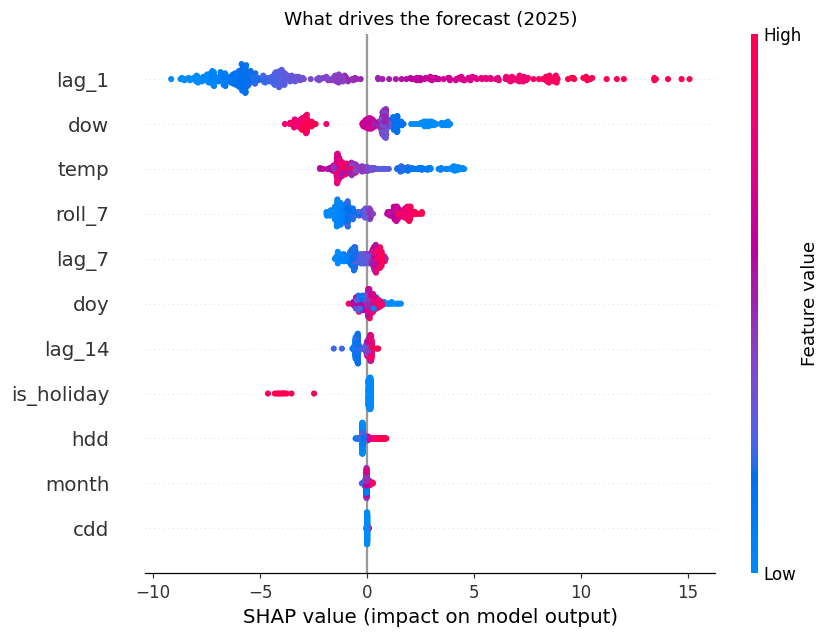

In [15]:
TEST_YEAR = TEST_YEARS[-1]
model = models[("LightGBM", TEST_YEAR)]
X_test = feat.loc[str(TEST_YEAR), FEATURES_ALL]

explainer = shap.TreeExplainer(model)
sv = explainer(X_test)

shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title(f"What drives the forecast ({TEST_YEAR})")
plt.tight_layout()
plt.savefig("figures/02_shap_beeswarm.png", bbox_inches="tight")
plt.show()

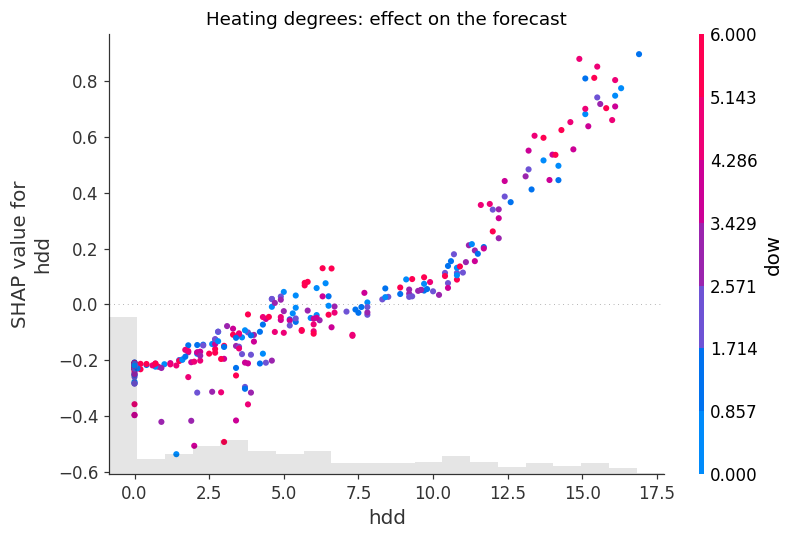

Below 15 degrees C, each degree colder adds about 0.46 GW to the forecast.


In [16]:
shap.plots.scatter(sv[:, "hdd"], color=sv[:, "dow"], show=False)
plt.title("Heating degrees: effect on the forecast")
plt.tight_layout()
plt.savefig("figures/03_shap_heating.png", bbox_inches="tight")
plt.show()

# How many GW does one colder degree add? Add up the three temperature
# features (they share credit) and fit a line on days below 15 degrees.
temp_effect = sv[:, "temp"].values + sv[:, "hdd"].values + sv[:, "cdd"].values
cold = X_test["temp"].values < 15
slope = np.polyfit(X_test["temp"].values[cold], temp_effect[cold], 1)[0]
print(f"Below 15 degrees C, each degree colder adds about {-slope:.2f} GW to the forecast.")

**Reading the heating effect.** 0.46 GW per degree is much lower than RTE's usual figure of about 2.4 GW per degree in winter. This is expected: yesterday's load (`lag_1`) already reflects the cold, since cold days follow cold days. SHAP only credits temperature with the change on top of what the lags already show. It also uses Paris temperature only, not a national average.

Coldest test day: 2025-01-14 (-1.4 degrees C), actual 78.0 GW


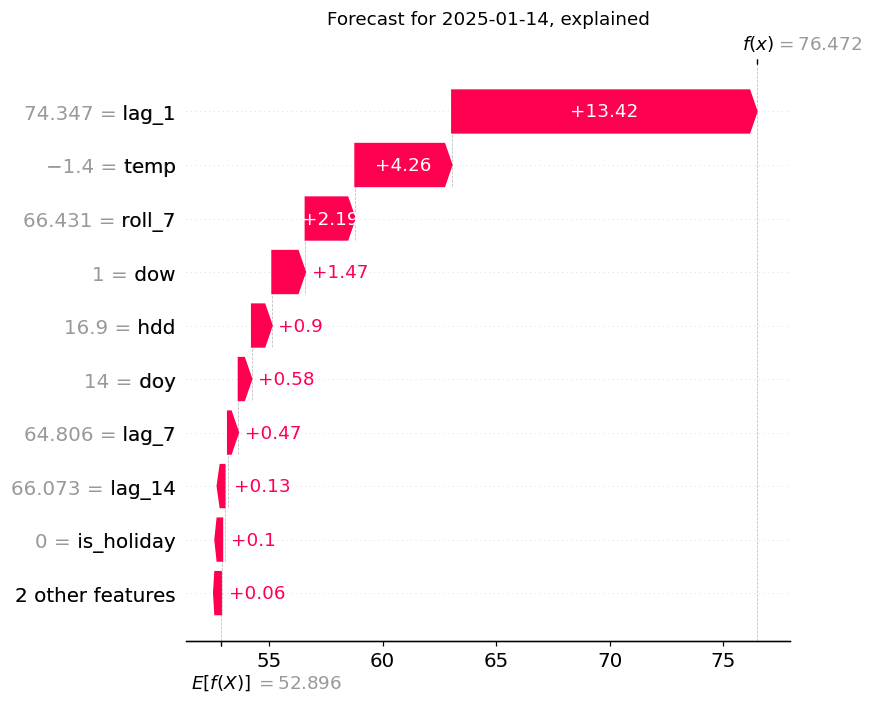

In [17]:
i = int(np.argmin(X_test["temp"].values))
coldest = X_test.index[i]
print(f"Coldest test day: {coldest.date()} ({X_test['temp'].iloc[i]:.1f} degrees C), "
      f"actual {feat.loc[coldest, 'load_gw']:.1f} GW")

shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.title(f"Forecast for {coldest.date()}, explained")
plt.tight_layout()
plt.savefig("figures/04_shap_coldest_day.png", bbox_inches="tight")
plt.show()

## Step 7. Look at the errors

In [18]:
p = preds[preds["model"] == "LightGBM"].copy()
p["error"] = p["actual"] - p["pred"]
p["abs_error"] = p["error"].abs()
p = p.join(feat[["temp", "is_holiday"]])
p["weekday"] = p.index.day_name()

top = (p.sort_values("abs_error", ascending=False).head(10)
       [["weekday", "actual", "pred", "error", "temp", "is_holiday"]].round(2))
top["what happened"] = ""   # fill in by hand after looking each day up
top.to_csv("results/top_errors.csv")
top

,weekday,actual,pred,error,temp,is_holiday,what happened
day,,,,,,,
2024-01-17,Wednesday,70.08,76.20,-6.11,1.2,0,
2024-01-18,Thursday,68.62,74.20,-5.58,-0.3,0,
2025-02-17,Monday,65.59,70.38,-4.80,1.8,0,
2025-01-22,Wednesday,68.78,73.53,-4.75,5.0,0,
2024-01-15,Monday,72.07,76.68,-4.61,1.0,0,
2025-11-24,Monday,63.13,67.39,-4.25,7.1,0,
2025-01-05,Sunday,57.27,61.22,-3.95,9.9,0,
2025-01-09,Thursday,63.75,67.64,-3.89,6.0,0,
2024-12-24,Tuesday,58.50,62.38,-3.88,7.0,0,


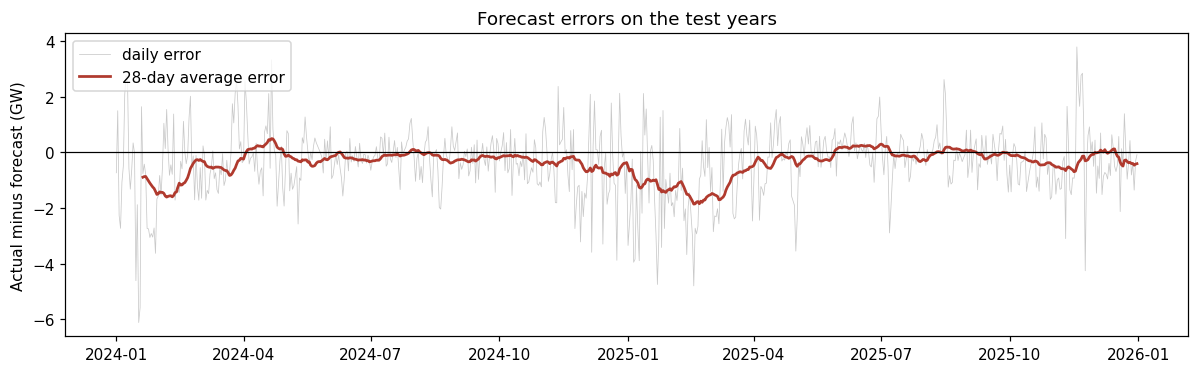

In [19]:
err = p["error"].sort_index()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(err.index, err, lw=0.5, color="#c9c9c9", label="daily error")
ax.plot(err.index, err.rolling(28, min_periods=20).mean(), lw=1.8, color="#b03a2e",
        label="28-day average error")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Actual minus forecast (GW)")
ax.set_title("Forecast errors on the test years")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figures/05_error_drift.png")
plt.show()

**Reading the errors.** All ten largest errors are over-forecasts, and nine fall between December and February. The drift plot shows the same thing: the 28-day average error dips below zero in both winters and stays near zero the rest of the year. A likely cause is that most training winters come from before the energy savings period (autumn 2022), when demand reacted more strongly to cold. Weighting recent years more, or a post-2022 feature, are the next things to test.

## Step 8. Save versions and results

In [20]:
from importlib.metadata import version
pkgs = ["pandas", "numpy", "lightgbm", "shap", "scikit-learn", "matplotlib", "holidays",
        "requests", "pyarrow"]
with open("requirements.txt", "w") as f:
    f.write("\n".join(f"{p}=={version(p)}" for p in pkgs) + "\n")
print(open("requirements.txt").read())

def to_markdown(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "| " + " | ".join("---" for _ in cols) + " |"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(f"{v:.2f}" if isinstance(v, float) else str(v) for v in r) + " |")
    return "\n".join(lines)

readme_table = results[results["test year"] == "average"].drop(columns="test year")
print(to_markdown(readme_table))

pandas==2.2.3
numpy==2.4.6
lightgbm==4.6.0
shap==0.54.1
scikit-learn==1.6.1
matplotlib==3.10.0
holidays==0.108
requests==2.32.4
pyarrow==23.0.1

| model | MAE (GW) | RMSE (GW) | MAPE (%) |
| --- | --- | --- | --- |
| Naive | 2.30 | 3.07 | 4.67 |
| Seasonal naive | 3.19 | 4.79 | 5.92 |
| LightGBM | 0.89 | 1.25 | 1.69 |
| LightGBM, no weather | 1.23 | 1.79 | 2.31 |
| LightGBM, monotone | 0.91 | 1.26 | 1.75 |
